# 09 · Stress windows

| Window | Dates | What happened |
|---|---|---|
| 2016 dry bulk trough | Nov 2015 - Jun 2016 | BDI record low; dilution and restructurings |
| COVID shock | Feb - May 2020 | Demand collapse, then a floating-storage spike in tankers |
| 2022 Russia sanctions | Feb - Dec 2022 | Tanker trade rerouted, product tanker boom |
| Red Sea disruption | Nov 2023 - Dec 2024 | Houthi attacks, Cape diversions, container rates spike |
| 2026 Hormuz crisis | 28 Feb 2026 - | Gulf transits halted after strikes on Iran; VLCC earnings above USD 400k/day |

In [1]:
import json, warnings
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from shiplab import charts
from shiplab.config import DATA
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3, "display.width", 140)
R = DATA / "results"
perf = pd.read_csv(R / "performance_by_period.csv")
strat = pd.read_parquet(R / "strategy_returns.parquet")
bench = pd.read_parquet(R / "benchmark_returns.parquet")
dsr = json.load(open(R / "deflated_sharpe.json"))
def row(period, series="Strategy"):
    return perf[(perf.period == period) & (perf.series == series)].iloc[0]

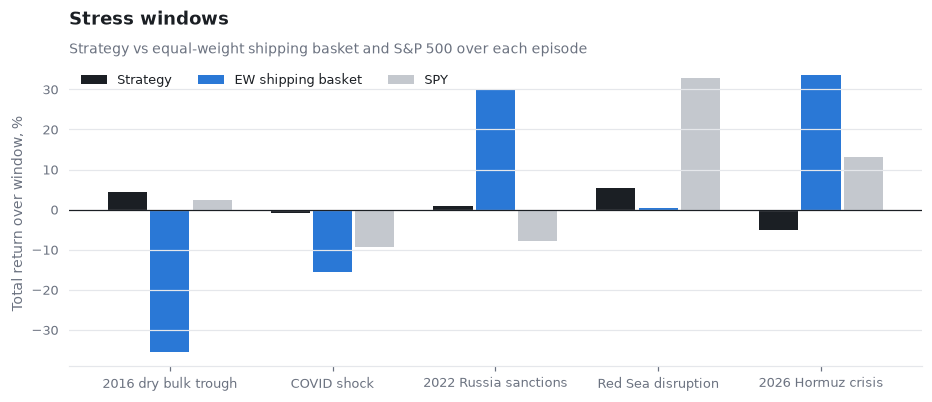

series,EW shipping basket,SPY,Strategy
window,,,
2016 dry bulk trough,-0.356,0.024,0.044
2022 Russia sanctions,0.302,-0.079,0.010
2026 Hormuz crisis,0.335,0.131,-0.050
COVID shock,-0.156,-0.093,-0.010
Red Sea disruption,0.005,0.328,0.053


In [2]:
stress = pd.read_csv(R / "stress.csv")
fig = charts.stress_bars(stress); charts.save(fig, "09_stress"); plt.show()
stress.pivot(index="window", columns="series", values="total_return").round(3)

The 2026 Hormuz episode illustrates the project's thesis: the dispersion between tanker owners
depended on *where each company's ships were* when the strait closed - an exposure invisible in
filings and Baltic indices, and directly observable from AIS.